# Jacobian structure

We'll make the `ase-iron` network and explore the different terms that influence the Jacobian.

## creating the net

In [1]:
import pynucastro as pyna

In [2]:
reaclib_lib = pyna.ReacLibLibrary()

all_reactants = ["p",
                 "he4", "c12", "o16", "ne20", "mg24", "si28", "s32",
                 "ar36", "ca40", "ti44", "cr48", "fe52", "ni56", "cu59", "zn60",
                 "al27", "p31", "cl35", "k39", "sc43", "v47", "mn51", "co55",
                 "n13", "na23"]

lib = reaclib_lib.linking_nuclei(all_reactants)

# in this list, we have the reactants, the actual reactants,
# and modified products that we will use instead
other_rates = [("c12(c12,n)mg23", "mg24"),
               ("o16(o16,n)s31", "s32"),
               ("o16(c12,n)si27", "si28")]

for r, mp in other_rates:
    _r = reaclib_lib.get_rate_by_name(r)
    forward_rate = pyna.ModifiedRate(_r, new_products=[mp],
                                     description=f"{r}(n,γ){mp}")
    derived_rate = pyna.DerivedRate(forward_rate, use_pf=True)
    lib += pyna.Library(rates=[forward_rate, derived_rate])

# C12+Ne20 and reverse
# (a,g) links between Na23 and Al27
# (a,g) links between Al27 and P31

rates_to_remove = ["p31(p,c12)ne20",
                   "si28(a,c12)ne20",
                   "ne20(c12,p)p31",
                   "ne20(c12,a)si28",
                   "na23(a,g)al27",
                   "al27(g,a)na23",
                   "al27(a,g)p31",
                   "p31(g,a)al27"]

for r in rates_to_remove:
    _r = lib.get_rate_by_name(r)
    lib.remove_rate(_r)

# iron group
iron_peak = ["n", "p", "he4",
             "mn51",
             "fe52", "fe53", "fe54", "fe55", "fe56",
             "co55", "co56", "co57",
             "ni56", "ni57", "ni58", "cu59", "zn60"]
lib += reaclib_lib.linking_nuclei(iron_peak)
weak_lib = pyna.TabularWeakLibrary(ordering=["ffn", "langanke", "oda"])
iron_weak_lib = weak_lib.linking_nuclei(set(iron_peak + all_reactants))
lib += iron_weak_lib

In [3]:
for r in lib.backward().get_rates():
    if fr := lib.get_rate_by_nuclei(r.products, r.reactants):
        lib.remove_rate(r)
        lib.add_rate(pyna.DerivedRate(fr, use_pf=True))

In [4]:
lib.eliminate_duplicates()

In [5]:
net = pyna.RateCollection(libraries=[lib])

In [6]:
net.make_ap_pg_approx(intermediate_nuclei=["cl35", "k39", "sc43", "v47"])
net.remove_nuclei(["cl35", "k39", "sc43", "v47"])

net.make_nn_g_approx(intermediate_nuclei=["fe53", "fe55", "ni57"])
net.remove_nuclei(["fe53", "fe55", "ni57"])

## The Jacobian structure

In [11]:
rho = 1.e8
T = 4.e9
comp = pyna.Composition(net.unique_nuclei, init="uniform")

In [12]:
state = pyna.ThermoState(rho=rho, T=T, comp=comp)

/home/zingale/development/pynucastro/pynucastro/rates/derived_rate.py:129: UserWarning: N13 partition function is not supported by tables: set log_pf = 0.0 by default
  warnings.warn(UserWarning(f'{nuc} partition function is not supported by tables: set log_pf = 0.0 by default'))
/home/zingale/development/pynucastro/pynucastro/rates/derived_rate.py:129: UserWarning: C12 partition function is not supported by tables: set log_pf = 0.0 by default
  warnings.warn(UserWarning(f'{nuc} partition function is not supported by tables: set log_pf = 0.0 by default'))


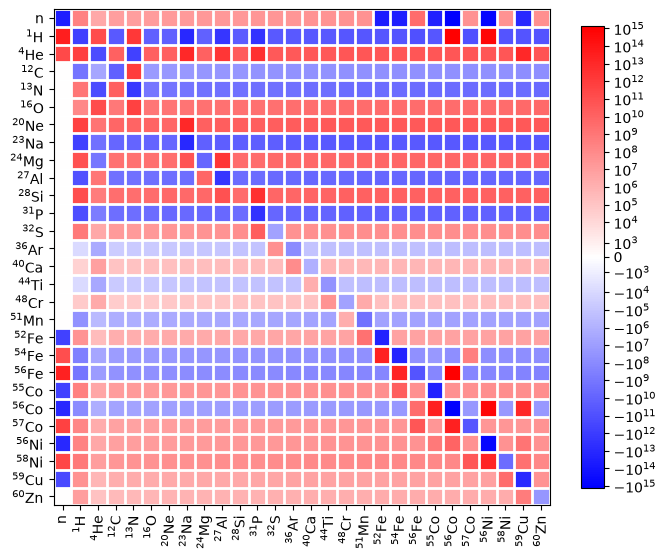

In [15]:
fig = net.plot_jacobian(state, screen_func=pyna.screening.screen.chugunov_2007, rate_scaling=1.e12)
fig.savefig("jacobian_with_comp_derivs.png")

/home/zingale/development/pynucastro/pynucastro/rates/derived_rate.py:129: UserWarning: N13 partition function is not supported by tables: set log_pf = 0.0 by default
  warnings.warn(UserWarning(f'{nuc} partition function is not supported by tables: set log_pf = 0.0 by default'))
/home/zingale/development/pynucastro/pynucastro/rates/derived_rate.py:129: UserWarning: C12 partition function is not supported by tables: set log_pf = 0.0 by default
  warnings.warn(UserWarning(f'{nuc} partition function is not supported by tables: set log_pf = 0.0 by default'))


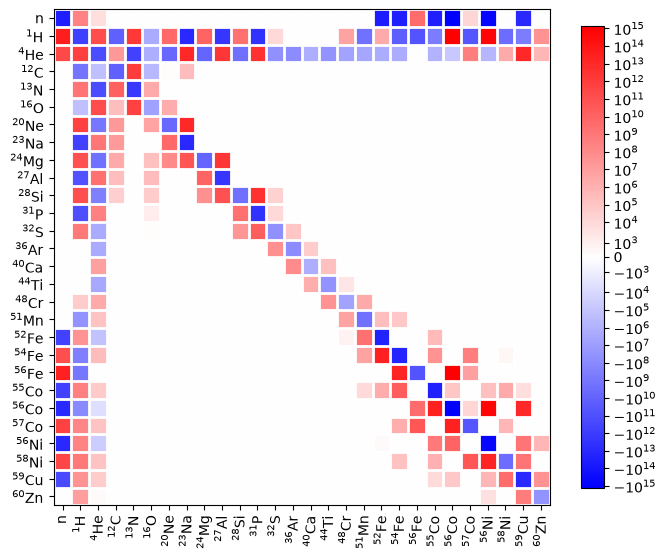

In [16]:
fig = net.plot_jacobian(state, screen_func=pyna.screening.screen.chugunov_2007, rate_scaling=1.e12,
                        include_screening_comp_derivs=False)
fig.savefig("jacobian_without_comp_derivs.png")

In [17]:
jac = net.evaluate_jacobian(state, screen_func=pyna.screening.screen.chugunov_2007)

/home/zingale/development/pynucastro/pynucastro/rates/derived_rate.py:129: UserWarning: N13 partition function is not supported by tables: set log_pf = 0.0 by default
  warnings.warn(UserWarning(f'{nuc} partition function is not supported by tables: set log_pf = 0.0 by default'))
/home/zingale/development/pynucastro/pynucastro/rates/derived_rate.py:129: UserWarning: C12 partition function is not supported by tables: set log_pf = 0.0 by default
  warnings.warn(UserWarning(f'{nuc} partition function is not supported by tables: set log_pf = 0.0 by default'))


In [20]:
jac.shape

(28, 28)

In [21]:
jac[-1,:]

array([ 0.00000000e+00,  9.11742754e+06,  1.29823962e+05,  3.88526798e+05,
        4.53281264e+05,  5.18035730e+05,  6.47544663e+05,  7.12299129e+05,
        7.77053595e+05,  8.41808062e+05,  9.06562528e+05,  9.71316994e+05,
        1.03607146e+06,  1.16558039e+06,  1.29508933e+06,  1.42459826e+06,
        1.55410719e+06,  1.61886166e+06,  1.68361612e+06,  1.68361612e+06,
        1.68361612e+06,  1.74837059e+06,  1.74837059e+06,  1.74837059e+06,
        1.81753547e+06,  1.81312506e+06,  5.35985591e+08, -2.63313504e+07])